# Notebook 01 — Latência e Performance em Inferência de ML

## Aula 01: Fundamentos de Latência e Performance
## 💼 Caso de Uso: Detecção de Fraude Bancária em Tempo Real

---

### 🎯 Objetivos

1. Definir **latência** e **throughput** no contexto de um sistema antifraude
2. Medir **p50, p95 e p99** da latência de inferência
3. Avaliar o **trade-off acurácia × latência × custo**
4. Aplicar **profiling** para encontrar gargalos no pipeline de inferência

### 📖 Cenário

Imagine um sistema de detecção de fraude bancária que analisa transações em
tempo real. Quando um cliente passa o cartão na maquininha, o sistema precisa
decidir **autorizar ou bloquear** a transação antes que o débito seja efetivado.

Se uma transação suspeita demora para ser sinalizada (latência alta), o banco
pode perder dinheiro ou credibilidade. O SLA típico do mercado de pagamentos é
**p99 < 100 ms** ponta-a-ponta — ou seja, 99% das decisões precisam sair em
menos de 100 ms, e a inferência do modelo deve responder em poucos milissegundos.

Nosso objetivo é reduzir a **latência de inferência** — o tempo de resposta do
modelo — para praticamente zero do ponto de vista do usuário.

Conforme Crankshaw et al. (2017) — *Clipper: A Low-Latency Online Prediction
Serving System*, a latência total é composta por:

$$L_{total} = L_{rede} + L_{pré} + L_{inferência} + L_{pós} + L_{serialização}$$

Neste notebook focamos em **$L_{inferência}$** — o componente que depende
diretamente da escolha e configuração do modelo de ML.

In [1]:
# Imports e configuração do ambiente
%load_ext autoreload
%autoreload 2

import cProfile
import io
import pstats
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent))

from src.data_preprocessing import DataPreprocessor
from src.utils import setup_output_dirs

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

np.random.seed(42)
dirs = setup_output_dirs(str(Path.cwd().parent))
print("Ambiente configurado.")

Ambiente configurado.


In [2]:
# Preparar dataset e modelos (setup rápido — o foco deste notebook é a inferência)
dataset_path = str(Path.cwd().parent / "data" / "raw" / "dataset.csv")

if not Path(dataset_path).exists():
    DataPreprocessor.generate_synthetic_dataset(
        output_path=dataset_path, n_samples=10_000, n_features=15,
        n_informative=10, random_state=42, fraud_rate=0.05,
    )
    print("Dataset sintético gerado.")

preprocessor = DataPreprocessor(random_state=42)
df = preprocessor.load_data(dataset_path)
df_clean = preprocessor.clean_data(df)
X, y = preprocessor.prepare_features(df_clean)
splits = preprocessor.split_data(X, y)

X_train, y_train = splits["X_train"], splits["y_train"]
X_test, y_test = splits["X_test"], splits["y_test"]
scaler = preprocessor.scaler

print(f"Dataset: {df.shape[0]:,} transações × {df.shape[1]} colunas")
print(f"Taxa de fraude: {df['target'].mean()*100:.1f}%")
print(f"Treino: {X_train.shape[0]:,}  |  Teste: {X_test.shape[0]:,}")

Dataset: 10,000 transações × 16 colunas
Taxa de fraude: 5.4%
Treino: 7,000  |  Teste: 2,000


---

## 1. Definições Básicas de Desempenho

### Latência

**Latência** é o tempo decorrido entre o sistema receber uma transação e
devolver a decisão (autorizar/bloquear). Medimos em **milissegundos (ms)**
usando `time.perf_counter()`, o relógio de maior resolução do Python.

No antifraude, cada milissegundo conta: enquanto o modelo pensa, o cliente
espera na maquininha.

### Throughput

**Throughput** (vazão) é o número de transações processadas por segundo
(**TPS** — *transactions per second*). Um banco grande processa milhões de
transações por dia; o throughput do modelo precisa acompanhar esse volume.

### Relação entre Latência e Throughput

| Conceito | Definição | Métrica |
|---|---|---|
| **Latência** | Tempo para processar **1** transação | ms/transação |
| **Throughput** | Quantas transações processamos **por segundo** | TPS |

Intuitivamente: se cada inferência leva 0,1 ms, o throughput teórico é
10.000 TPS (1.000 ms / 0,1 ms). Na prática, overhead de I/O, GC e contenção
reduzem esse valor.

Vamos medir ambos para nosso modelo de Regressão Logística.

In [4]:
# Treinar Regressão Logística (modelo rápido para baseline)
# A regressão logística é um algoritmo de estatística e machine learning utilizado para classificação.
# Em vez de prever um número contínuo (como o preço de uma casa), ela calcula a probabilidade de um evento acontecer, resultando em respostas categóricas (sim/não, verdadeiro/falso, 0/1)
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)

# --- Latência de inferência para UMA transação ---
# Warm-up: Executa 50 chamadas de predict_proba em um unico exemplo para “aquecer” caches e reduzir o custo das primeiras execucoes.
for _ in range(50):
    model_lr.predict_proba(X_test[:1])

# Seleciona uma transacao: x_single = X_test[0:1] garante formato 2D esperado pelo modelo (1 amostra, 15 features)
# Medir latência de uma única transação
x_single = X_test[0:1]  # shape (1, 15)

# Mede o tempo: usa time.perf_counter() antes e depois da inferencia para obter alta resolucao
# Alta resolucao significa que o relogio tem granularidade muito fina (sub-milissegundo, tipicamente microssegundos) e baixa variacao entre leituras, o que permite medir tempos muito curtos com mais precisao.
t0 = time.perf_counter()
proba = model_lr.predict_proba(x_single)[0, 1]

# Converte o tempo para milissegundos multiplicando por 1000
latencia_ms = (time.perf_counter() - t0) * 1000

# Se proba (probabilidade de fraude) for maior ou igual a 0.5, a decisao vira " BLOQUEAR"; caso contrario, "AUTORIZ
decisao = "🚫 BLOQUEAR" if proba >= 0.5 else "✅ AUTORIZAR"
print(f"Transação analisada:")
print(f"  Probabilidade de fraude: {proba:.4f}")
print(f"  Decisão: {decisao}")
print(f"  Latência de inferência: {latencia_ms:.3f} ms")

Transação analisada:
  Probabilidade de fraude: 0.6598
  Decisão: 🚫 BLOQUEAR
  Latência de inferência: 0.107 ms


In [5]:
# --- Throughput: quantas transações/segundo conseguimos processar? ---
N = 1000

# Mede o tempo total para fazer 1000 inferencias individuais (X_test[i:i+1]), guardando em t_oneone
t_start = time.perf_counter()
for i in range(N):
    model_lr.predict_proba(X_test[i : i + 1])
t_oneone = time.perf_counter() - t_start

# Mede o tempo para inferir as 1000 de uma vez (X_test[:N]), guardando em t_batch
t_start = time.perf_counter()
model_lr.predict_proba(X_test[:N])
t_batch = time.perf_counter() - t_start

# Converte tempo total em transacoes por segundo
tps_oneone = N / t_oneone
tps_batch = N / t_batch

print(f"Throughput (uma-a-uma): {tps_oneone:,.0f} TPS  ({t_oneone*1000:.1f} ms para {N} tx)")
print(f"Throughput (batch):     {tps_batch:,.0f} TPS  ({t_batch*1000:.1f} ms para {N} tx)")
print(f"\nGanho de batch vs. uma-a-uma: {tps_batch/tps_oneone:.1f}×")
print(f"\n💡 Batching aumenta throughput, mas no antifraude real-time")
print(f"   cada transação chega individualmente — latência por transação importa mais.")

Throughput (uma-a-uma): 37,097 TPS  (27.0 ms para 1000 tx)
Throughput (batch):     5,149,332 TPS  (0.2 ms para 1000 tx)

Ganho de batch vs. uma-a-uma: 138.8×

💡 Batching aumenta throughput, mas no antifraude real-time
   cada transação chega individualmente — latência por transação importa mais.


---

## 2. Métricas de Latência: p50, p95, p99

Uma única medição de latência não diz nada — latência é uma **distribuição**.
Os percentis revelam o comportamento real do sistema sob diferentes condições:

| Métrica | Significado | Uso no antifraude |
|---|---|---|
| **p50 (mediana)** | Metade das transações responde em ≤ X ms | Saúde geral do sistema |
| **p95** | 95% das transações em ≤ X ms | Alvo de produto / engenharia |
| **p99** | 99% das transações em ≤ X ms | **SLA contratual** |
| **p99.9 / max** | Pior caso observado | Detecção de anomalias de infra |

### Por que não usar a média?

A média esconde a cauda da distribuição. Se 99% das transações respondem em
0,1 ms mas 1% leva 50 ms, a média é ~0,6 ms — parece ótimo! Mas o SLA de
p99 < 5 ms é violado. Em escala de 10 milhões de transações/dia, 1% significa
**100.000 clientes** esperando demais.

Conforme Dean & Barroso (2013) — *The Tail at Scale*:
> "Even rare high-latency events can dominate overall service performance
> at scale."

Vamos rodar 1.000 inferências e observar a distribuição completa.

In [6]:
# Coletar latências de N inferências individuais
N = 1000
latencias = []

# Warm-up
for _ in range(50):
    model_lr.predict_proba(X_test[:1])

# Mede a latencia de inferencia amostra por amostra
# Para cada uma das N transacoes, pega uma unica linha de X_test.
# Marca o tempo inicial, executa predict_proba, mede o tempo decorrido.
# Converte o tempo para milissegundos e adiciona na lista latencias
for i in range(N):
    x = X_test[i : i + 1]
    t0 = time.perf_counter()
    model_lr.predict_proba(x)
    latencias.append((time.perf_counter() - t0) * 1000)

latencias = np.array(latencias)

# Calcular percentis
#p50, p95, p99, p99.9: percentis da latencia (mediana, 95%, 99%, 99.9%).
# max: maior latencia observada.
# mean: media das latencias.
# std (jitter): desvio padrao, usado como medida de variabilidade (jitter)
percentis = {
    "p50": np.percentile(latencias, 50),
    "p95": np.percentile(latencias, 95),
    "p99": np.percentile(latencias, 99),
    "p99.9": np.percentile(latencias, 99.9),
    "max": latencias.max(),
    "mean": latencias.mean(),
    "std (jitter)": latencias.std(),
}

print(f"Latência de inferência — LogisticRegression ({N} transações)")
print("=" * 50)
for nome, valor in percentis.items():
    print(f"  {nome:12s}: {valor:.4f} ms")

# SLA check
SLA_MS = 5.0  # exemplo: modelo deve responder em < 5 ms (p99)
violacoes = (latencias > SLA_MS).sum()
print(f"\n📊 SLA p99 < {SLA_MS} ms: {'✅ CUMPRIDO' if percentis['p99'] < SLA_MS else '❌ VIOLADO'}")
print(f"   Transações acima do SLA: {violacoes}/{N} ({violacoes/N*100:.2f}%)")

Latência de inferência — LogisticRegression (1000 transações)
  p50         : 0.0244 ms
  p95         : 0.0280 ms
  p99         : 0.0414 ms
  p99.9       : 0.4542 ms
  max         : 0.5547 ms
  mean        : 0.0262 ms
  std (jitter): 0.0225 ms

📊 SLA p99 < 5.0 ms: ✅ CUMPRIDO
   Transações acima do SLA: 0/1000 (0.00%)


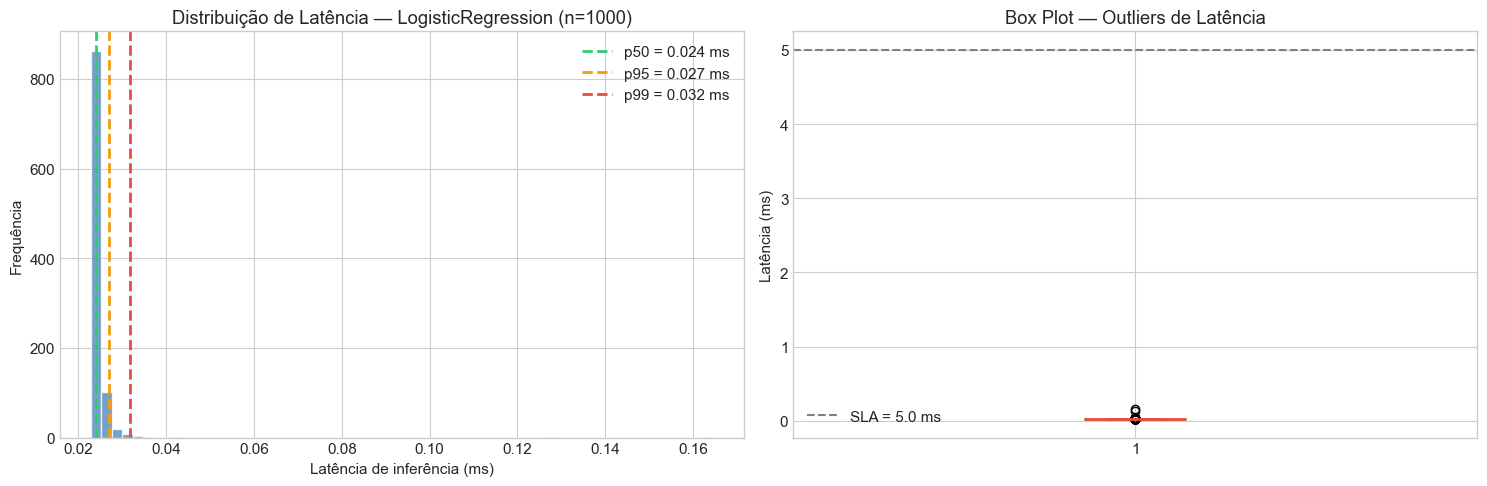

In [6]:
# Visualizar distribuição de latência com percentis marcados
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Histograma com linhas de percentil
axes[0].hist(latencias, bins=60, color="steelblue", alpha=0.75, edgecolor="white")
marcadores = [(50, "#2ecc71", "p50"), (95, "#f39c12", "p95"), (99, "#e74c3c", "p99")]
for q, cor, label in marcadores:
    v = np.percentile(latencias, q)
    axes[0].axvline(v, color=cor, linestyle="--", linewidth=2,
                    label=f"{label} = {v:.3f} ms")
axes[0].set_xlabel("Latência de inferência (ms)")
axes[0].set_ylabel("Frequência")
axes[0].set_title(f"Distribuição de Latência — LogisticRegression (n={N})")
axes[0].legend()

# (b) Box plot para visualizar outliers
axes[1].boxplot(latencias, vert=True, patch_artist=True,
                boxprops=dict(facecolor="steelblue", alpha=0.7),
                medianprops=dict(color="#e74c3c", linewidth=2))
axes[1].axhline(SLA_MS, color="gray", linestyle="--", label=f"SLA = {SLA_MS} ms")
axes[1].set_ylabel("Latência (ms)")
axes[1].set_title("Box Plot — Outliers de Latência")
axes[1].legend()

plt.tight_layout()
fig.savefig(str(dirs["figures"] / "01_latency_percentiles.png"), dpi=150, bbox_inches="tight")
plt.show()

---

## 3. Trade-off: Latência × Acurácia × Custo

Modelos mais complexos tendem a ter melhor acurácia, mas pagam o preço em
latência de inferência e custo computacional. No antifraude:

### Regressão Logística — Complexidade: $O(d)$

Funciona calculando uma combinação linear das features seguida de uma função sigmoide:

$$P(y=1) = \sigma(w_0 + w_1 x_1 + w_2 x_2 + ... + w_d x_d)$$

Na inferência, é apenas uma multiplicação de vetor (pesos × features) + soma + aplicação
da sigmoide. Por isso a complexidade é **linear no número de features** ($d$).
É o modelo mais rápido para inferência.

### Random Forest — Complexidade: $O(t \cdot \log n)$

Consiste em $t$ árvores de decisão independentes. Cada árvore percorre nós desde a raiz
até uma folha, fazendo comparações do tipo `feature_i < threshold`. Em árvores balanceadas,
a profundidade média é $\log n$ (onde $n$ é o número de amostras usadas no treino).

Na inferência:
- Percorre as $t$ árvores
- Cada árvore faz ~$\log n$ comparações
- Agrega os votos (média das probabilidades)

Como as árvores são independentes, **pode paralelizar** (`n_jobs`), mas ainda assim
é mais lento que regressão logística.

### Gradient Boosting — Complexidade: $O(t \cdot d_{max})$

Também usa $t$ árvores, mas elas são **sequenciais** (cada árvore corrige os erros
da anterior). Na inferência:
- Percorre as $t$ árvores **em ordem**
- Cada árvore tem profundidade fixa $d_{max}$ (geralmente 3–8)
- Soma as predições de todas as árvores

Diferente do Random Forest, **não paraleliza** na inferência porque as árvores são
aditivas. A complexidade é $O(t \cdot d_{max})$, onde $d_{max}$ é a profundidade máxima.

### O dilema em produção

Um modelo levemente menos acurado e **muito mais rápido** costuma valer mais
que um modelo "perfeito" que estoura o SLA. Um Random Forest com AUC 0,98 que
leva 2 ms por transação pode ser pior que uma Logistic Regression com AUC 0,95
que leva 0,05 ms — porque em picos de carga, o RF pode estourar o p99.

### Custo computacional

Latência ↔ custo de infra. Modelo mais lento = mais CPU/GPU = mais
dinheiro. Em 10M transações/dia, cada 0,1 ms a mais se acumula.

Vamos comparar três modelos treinados no mesmo dataset.

In [7]:
# Treinar e comparar 3 modelos: acurácia (AUC), latência (p50/p99), throughput
modelos = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest (100)": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=1
    ),
    "GradientBoosting (100)": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    ),
}

resultados = []
N_INFER = 500

for nome, modelo in modelos.items():
    # Treinar
    t0 = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo_treino = time.perf_counter() - t0

    # Acurácia
    auc = roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])

    # Latência de inferência (warm-up + medição)
    for _ in range(30):
        modelo.predict_proba(X_test[:1])

    lats = []
    for i in range(N_INFER):
        x = X_test[i : i + 1]
        t0 = time.perf_counter()
        modelo.predict_proba(x)
        lats.append((time.perf_counter() - t0) * 1000)
    lats = np.array(lats)

    resultados.append({
        "modelo": nome,
        "AUC": round(auc, 4),
        "p50_ms": round(np.percentile(lats, 50), 4),
        "p95_ms": round(np.percentile(lats, 95), 4),
        "p99_ms": round(np.percentile(lats, 99), 4),
        "TPS": int(1000 / lats.mean()),
        "treino_s": round(tempo_treino, 2),
    })

df_resultados = pd.DataFrame(resultados)
print(df_resultados.to_string(index=False))

                modelo    AUC  p50_ms  p95_ms  p99_ms   TPS  treino_s
    LogisticRegression 0.8211  0.0250  0.0299  0.0583 37184      0.01
    RandomForest (100) 0.8908  2.7190  5.2660  7.8916   315      1.18
GradientBoosting (100) 0.8926  0.0658  0.0706  0.0810 14819      2.55


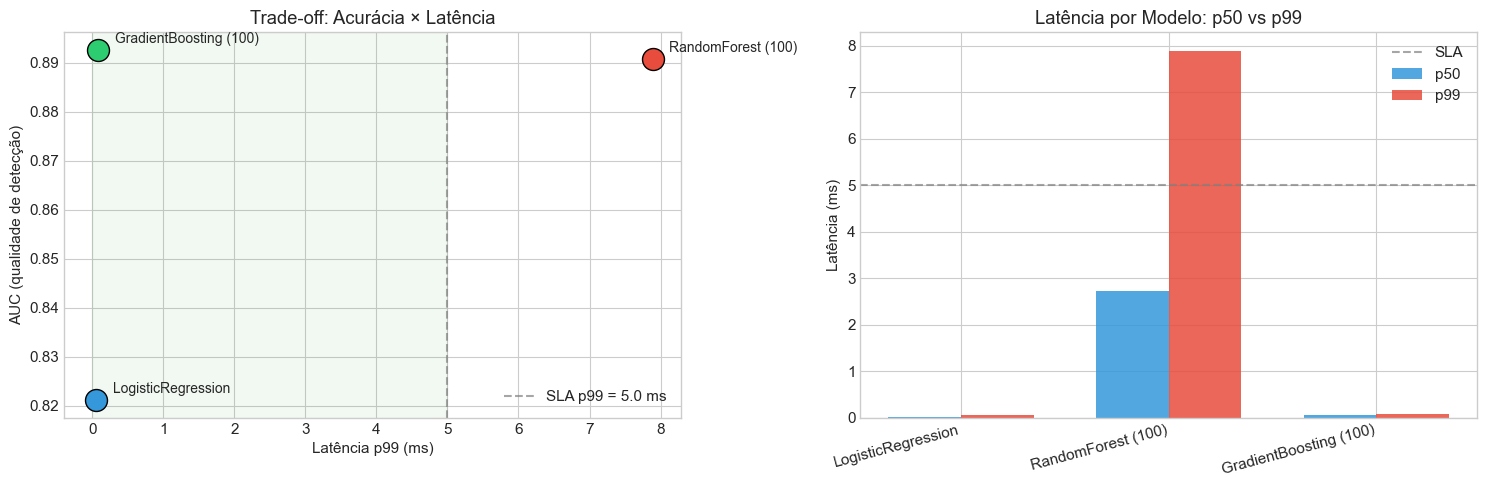

In [8]:
# Visualizar trade-off: AUC vs Latência p99 + custo relativo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cores = ["#3498db", "#e74c3c", "#2ecc71"]

# (a) Scatter: AUC vs p99
for i, row in df_resultados.iterrows():
    axes[0].scatter(row["p99_ms"], row["AUC"], s=250, c=cores[i],
                    edgecolors="black", linewidth=1, zorder=5)
    axes[0].annotate(row["modelo"],
                     (row["p99_ms"], row["AUC"]),
                     xytext=(12, 5), textcoords="offset points", fontsize=10)

# Região de SLA
sla_p99 = 5.0
axes[0].axvline(sla_p99, color="gray", linestyle="--", alpha=0.7,
                label=f"SLA p99 = {sla_p99} ms")
axes[0].axvspan(0, sla_p99, alpha=0.05, color="green")
axes[0].set_xlabel("Latência p99 (ms)")
axes[0].set_ylabel("AUC (qualidade de detecção)")
axes[0].set_title("Trade-off: Acurácia × Latência")
axes[0].legend()

# (b) Barras: latência p50 vs p99 por modelo
x_pos = np.arange(len(df_resultados))
width = 0.35
axes[1].bar(x_pos - width/2, df_resultados["p50_ms"], width,
            label="p50", color="#3498db", alpha=0.85)
axes[1].bar(x_pos + width/2, df_resultados["p99_ms"], width,
            label="p99", color="#e74c3c", alpha=0.85)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_resultados["modelo"], rotation=15, ha="right")
axes[1].set_ylabel("Latência (ms)")
axes[1].set_title("Latência por Modelo: p50 vs p99")
axes[1].axhline(sla_p99, color="gray", linestyle="--", alpha=0.7, label="SLA")
axes[1].legend()

plt.tight_layout()
fig.savefig(str(dirs["figures"] / "01_tradeoff_accuracy_latency.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Análise de custo: projeção de custo computacional diário
TX_POR_DIA = 10_000_000  # 10M transações/dia (banco de médio porte)
CUSTO_CPU_HORA = 0.05    # USD por vCPU-hora (referência cloud)

print("📊 Projeção de custo computacional (10M transações/dia)")
print("=" * 65)

for _, row in df_resultados.iterrows():
    # Tempo total de CPU por dia (horas)
    # Multiplica o número de transações pela latência mediana em milissegundos
    tempo_total_ms = TX_POR_DIA * row["p50_ms"]
    
    tempo_total_h = tempo_total_ms / 1000 / 3600
    custo_dia = tempo_total_h * CUSTO_CPU_HORA
    custo_mes = custo_dia * 30

    print(f"\n  {row['modelo']}:")
    print(f"    Latência p50: {row['p50_ms']:.4f} ms")
    print(f"    CPU-horas/dia: {tempo_total_h:.1f} h")
    print(f"    Custo/dia: US$ {custo_dia:.2f}  |  Custo/mês: US$ {custo_mes:.2f}")

print(f"\n💡 A diferença de latência entre modelos, multiplicada por milhões")
print(f"   de transações, se traduz em custo real de infraestrutura.")

📊 Projeção de custo computacional (10M transações/dia)

  LogisticRegression:
    Latência p50: 0.0250 ms
    CPU-horas/dia: 0.1 h
    Custo/dia: US$ 0.00  |  Custo/mês: US$ 0.10

  RandomForest (100):
    Latência p50: 2.7190 ms
    CPU-horas/dia: 7.6 h
    Custo/dia: US$ 0.38  |  Custo/mês: US$ 11.33

  GradientBoosting (100):
    Latência p50: 0.0658 ms
    CPU-horas/dia: 0.2 h
    Custo/dia: US$ 0.01  |  Custo/mês: US$ 0.27

💡 A diferença de latência entre modelos, multiplicada por milhões
   de transações, se traduz em custo real de infraestrutura.


---

## 4. Profiling: Onde o Tempo Está Sendo Gasto?

Medir percentis responde **quanto** tempo demora. Profiling responde
**onde** o tempo é gasto dentro do código.

Usamos `cProfile` (da biblioteca padrão do Python) para identificar as
funções mais custosas no pipeline de inferência. Esse é o ponto de partida
para qualquer otimização: não adianta otimizar uma função que consome 1%
do tempo enquanto outra consome 80%.

### Leitura do output do cProfile

| Coluna | Significado |
|---|---|
| `ncalls` | Número de vezes que a função foi chamada |
| `tottime` | Tempo total gasto **na função** (sem subchamadas) |
| `cumtime` | Tempo cumulativo (função + tudo que ela chama) |
| `percall` | Tempo médio por chamada |

O que procurar: funções com `cumtime` alto são os gargalos do pipeline.

In [13]:
# Profiling do pipeline de inferência com cProfile
# Vamos perfilar 500 inferências individuais (cenário real-time)

def pipeline_inferencia(modelo, X, n=500):
    """Simula o pipeline de inferência real-time para n transações."""
    for i in range(n):
        x = X[i : i + 1]
        proba = modelo.predict_proba(x)[0, 1]
        decisao = "BLOQUEAR" if proba >= 0.5 else "AUTORIZAR"


# --- LogisticRegression ---
print("=" * 60)
print("PROFILING: LogisticRegression (500 inferências)")
print("=" * 60)

profiler = cProfile.Profile()
profiler.enable()
pipeline_inferencia(model_lr, X_test, n=500)
profiler.disable()

buf = io.StringIO()
stats_lr = pstats.Stats(profiler, stream=buf).sort_stats("cumulative")
stats_lr.print_stats(10)
print(buf.getvalue())

PROFILING: LogisticRegression (500 inferências)


ValueError: Another profiling tool is already active

In [11]:
# --- Profiling comparativo: RandomForest ---
modelo_rf = modelos["RandomForest (100)"]

print("=" * 60)
print("PROFILING: RandomForest (500 inferências)")
print("=" * 60)

profiler_rf = cProfile.Profile()
profiler_rf.enable()
pipeline_inferencia(modelo_rf, X_test, n=500)
profiler_rf.disable()

buf = io.StringIO()
stats_rf = pstats.Stats(profiler_rf, stream=buf).sort_stats("cumulative")
stats_rf.print_stats(10)
print(buf.getvalue())

print("\n💡 Compare o 'cumtime' da função predict_proba entre os dois modelos.")
print("   O RandomForest chama internamente cada árvore — veja o volume de ncalls.")

PROFILING: RandomForest (500 inferências)


NameError: name 'pipeline_inferencia' is not defined

In [ ]:
# Salvar splits para os próximos notebooks
processed_dir = Path.cwd().parent / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
for name, arr in splits.items():
    np.save(str(processed_dir / f"{name}.npy"), arr)
print(f"Splits salvos em {processed_dir}")

---

## 📋 Resumo

### O que cobrimos

| Tópico | Conceito-chave | Aplicação no antifraude |
|---|---|---|
| **Definições** | Latência (ms/tx), Throughput (TPS) | Tempo de decisão por transação |
| **Percentis** | p50, p95, p99 — SLA vive no p99, não na média | 1% de violação = 100k clientes/dia |
| **Trade-off** | Acurácia ↔ Latência ↔ Custo | Modelo rápido > modelo perfeito que estoura SLA |
| **Profiling** | `cProfile` + `pstats` | Identificar gargalos antes de otimizar |

### Lições principais

1. **Latência de inferência** é o que o usuário sente — medir com `perf_counter()` e analisar percentis
2. O **p99**, não a média, define se o sistema cumpre o SLA
3. Modelo mais preciso ≠ melhor em produção quando o p99 estoura o SLA
4. **Profiling primeiro, otimização depois** — não otimize às cegas

### 📚 Referências

- Crankshaw, D. et al. (2017). *Clipper: A Low-Latency Online Prediction Serving System*. NSDI '17.
- Dean, J. & Barroso, L. A. (2013). *The Tail at Scale*. Communications of the ACM, 56(2), 74-80.
- Reddi, V. J. et al. (2020). *MLPerf Inference Benchmark*. ISCA '20.